# TD06 — Support Vector Machines

## Objectif

Sur un même jeu de données 2D, comparer le **perceptron** et le **SVM** (cours « 6 - Support Vector Machines ») :

- sur des données **séparables**, le perceptron s'arrête sur *une* droite séparatrice quelconque, alors que le SVM cherche *la* droite de **marge maximale** ;
- on code le SVM à marge souple en minimisant par **descente de gradient** la perte

$$E(w, b) = \frac{1}{2}\|w\|^2 + \frac{C}{N} \sum_{i=1}^N \max\big(0,\ 1 - t_i z_i\big), \qquad z_i = w \cdot x_i + b.$$

**Notations**
- Cible $t$, sortie (prédiction) $y$, score $z = w \cdot x + b$ (biais en $+b$, comme au TD02).
- ⚠️ **Cibles $t \in \{-1, +1\}$** dans tout ce TD, et non plus $\{0, 1\}$ comme au TD01. Un point est bien classé si et seulement si $t\,z > 0$.
- Dans le code : `lr` pour le pas d'apprentissage, `C` pour $C$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Alias de types pour les tableaux numpy
Vec = np.ndarray[tuple[int], np.dtype[np.float64]]        # vecteur 1D de flottants
Mat = np.ndarray[tuple[int, int], np.dtype[np.float64]]   # matrice 2D de flottants
VecInt = np.ndarray[tuple[int], np.dtype[np.int64]]       # vecteur 1D d'entiers (cibles ±1)

## Préambule : données et outils fournis

Rien à coder dans cette section : exécutez les cellules et lisez le code.

### Génération des données

`gen_donnees(n, ecart, seed, n_bruit)` tire `n` points 2D en deux classes ($t = +1$ et $t = -1$), de part et d'autre de la droite $x_1 + x_2 = 0$, en laissant une **bande vide** de largeur `ecart` entre les deux classes : le jeu est donc **séparable**, mais de justesse. Les classes sont étirées le long de la frontière.

`n_bruit` inverse l'étiquette de `n_bruit` points tirés au hasard (utilisé plus tard). Avec la même graine, les points `X` sont les mêmes, seules les étiquettes changent.

On utilise **peu** de points d'entraînement (24) et **beaucoup** de points de test (500), tirés de la même distribution : on pourra ainsi mesurer finement la généralisation.

In [2]:
def gen_donnees(n: int, ecart: float, seed: int, n_bruit: int = 0) -> tuple[Mat, VecInt]:
    rng = np.random.default_rng(seed)
    u = np.array([1.0, 1.0]) / np.sqrt(2)    # normale à la vraie frontière x1 + x2 = 0
    v = np.array([-1.0, 1.0]) / np.sqrt(2)   # direction de la vraie frontière
    t = np.where(np.arange(n) < n // 2, 1, -1)
    a = t * (ecart / 2 + np.abs(rng.normal(0.0, 1.0, n)))   # distance signée à la frontière
    c = rng.normal(0.0, 2.0, n)                              # position le long de la frontière
    X = a[:, None] * u + c[:, None] * v
    perm = rng.permutation(n)
    X, t = X[perm], t[perm]
    if n_bruit > 0:
        idx = rng.choice(n, size=n_bruit, replace=False)
        t = t.copy()
        t[idx] = -t[idx]
    return X, t


ECART = 0.6
X_train, t_train = gen_donnees(24, ECART, seed=4)
X_test, t_test = gen_donnees(500, ECART, seed=1000)
print("train :", X_train.shape, "test :", X_test.shape, "cibles :", np.unique(t_train))

train : (24, 2) test : (500, 2) cibles : [-1  1]


### Affichage

`plot_modele(ax, X, t, w, b, ...)` affiche les points (orange : $t = +1$, bleu : $t = -1$, comme dans les figures du cours) et la frontière $z = w \cdot x + b = 0$ (trait plein). Options :
- `marges=True` : les droites $z = \pm 1$ en pointillés ;
- `supports=True` : entoure les points tels que $t\,z \le 1 + \varepsilon$ (vecteurs de support), avec $\varepsilon$ = `eps`.

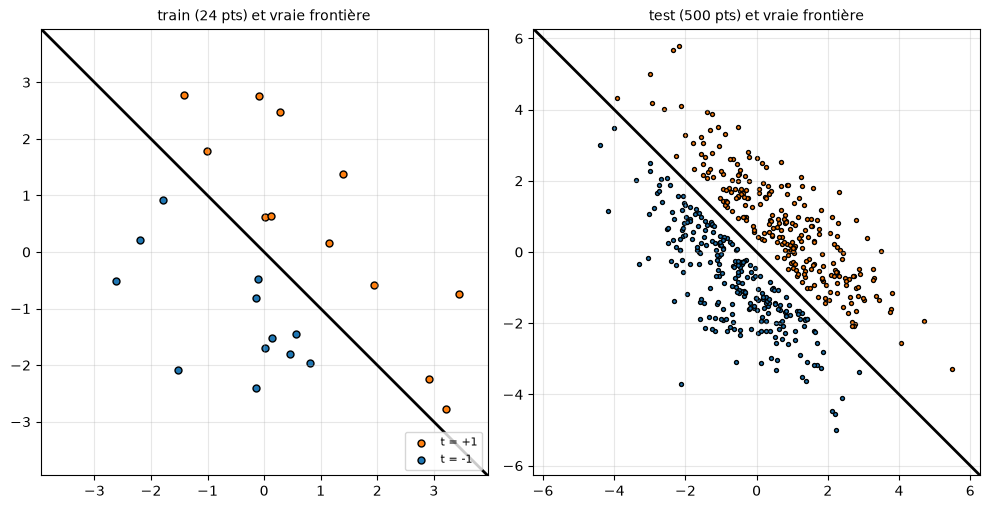

In [3]:
def plot_modele(ax, X, t, w, b, titre="", marges=False, supports=False, eps=0.05):
    taille = 25 if len(X) <= 100 else 8
    ax.scatter(X[t == 1, 0], X[t == 1, 1], c="tab:orange", edgecolors="k", s=taille, label="t = +1")
    ax.scatter(X[t == -1, 0], X[t == -1, 1], c="tab:blue", edgecolors="k", s=taille, label="t = -1")
    lim = np.abs(X).max() + 0.5
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    w = np.asarray(w, dtype=float)
    if np.linalg.norm(w) > 0:
        # point de la droite w·x + b = niveau le plus proche de l'origine
        def droite(niveau, **style):
            p0 = (niveau - b) * w / (w @ w)
            ax.axline(p0, p0 + np.array([-w[1], w[0]]), **style)
        droite(0.0, color="k", lw=2)
        if marges:
            droite(1.0, color="k", lw=1, ls="--")
            droite(-1.0, color="k", lw=1, ls="--")
    if supports:
        sv = t * (X @ w + b) <= 1 + eps
        ax.scatter(X[sv, 0], X[sv, 1], s=180, facecolors="none", edgecolors="crimson", lw=1.5,
                   label="vecteurs de support")
    if titre:
        ax.set_title(titre, fontsize=10)


fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_modele(axes[0], X_train, t_train, np.array([1.0, 1.0]), 0.0, titre="train (24 pts) et vraie frontière")
plot_modele(axes[1], X_test, t_test, np.array([1.0, 1.0]), 0.0, titre="test (500 pts) et vraie frontière")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Perceptron et accuracy

Le perceptron a été codé au TD01 : on en fournit ici une version vectorielle, avec cibles $\pm 1$ et biais en $+b$. Pour chaque point mal classé ($t\,z \le 0$) : $w \leftarrow w + \texttt{lr}\; t\,x$, $b \leftarrow b + \texttt{lr}\; t$ (règle de Rosenblatt, cours §4).

- `fit(X, t, lr, max_epochs, seed)` parcourt les points dans un ordre mélangé selon `seed` (nouvel ordre à chaque époque), s'arrête dès qu'une époque se fait sans erreur et renvoie le nombre d'époques effectuées. `self.erreurs` contient le nombre d'erreurs de chaque époque.
- `accuracy(y, t)` renvoie la proportion (entre 0 et 1) de prédictions correctes.

In [4]:
class Perceptron:
    def __init__(self, d: int):
        self.w = np.zeros(d)
        self.b = 0.0
        self.erreurs = []

    def predict(self, X: Mat) -> VecInt:
        return np.where(X @ self.w + self.b >= 0, 1, -1)

    def fit(self, X: Mat, t: VecInt, lr: float = 0.1, max_epochs: int = 100, seed: int = 0) -> int:
        rng = np.random.default_rng(seed)
        self.erreurs = []
        for epoque in range(1, max_epochs + 1):
            n_err = 0
            for i in rng.permutation(len(X)):
                if t[i] * (X[i] @ self.w + self.b) <= 0:
                    self.w = self.w + lr * t[i] * X[i]
                    self.b = self.b + lr * t[i]
                    n_err += 1
            self.erreurs.append(n_err)
            if n_err == 0:
                return epoque
        return max_epochs


def accuracy(y: VecInt, t: VecInt) -> float:
    return float(np.mean(y == t))

## 1. Données séparables : le perceptron et la marge

### 1.1 Marge géométrique

La marge d'un séparateur $(w, b)$ sur un jeu $(X, t)$ est la distance (signée) du point le plus proche à la frontière (cours §2.1) :

$$\text{marge}(w, b) = \min_i \frac{t_i\,(w \cdot x_i + b)}{\|w\|}$$

Elle est négative si au moins un point est mal classé.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 1</legend>

Complétez `marge(w, b, X, t)`, en une ou deux lignes vectorisées (sans boucle).

</fieldset>

In [5]:
def marge(w: Vec, b: float, X: Mat, t: VecInt) -> float:
    # BEGIN
    # raise NotImplementedError
    ## Indice : utiliser np.min et np.linalg.norm
    z = X @ w + b
    return float(np.min(t * z) / np.linalg.norm(w))
    # END

#### Vérification de `marge`

Trois points sur l'axe $x_1$, frontière $x_1 = 0$ : le point le plus proche est à distance 1. Multiplier $(w, b)$ par 2 ne change pas la marge ; décaler la frontière en $x_1 = 2$ classe mal le point $(1, 0)$.

In [6]:
def check_marge():
    X = np.array([[1.0, 0.0], [3.0, 0.0], [-2.0, 0.0]])
    t = np.array([1, 1, -1])
    assert np.isclose(marge(np.array([1.0, 0.0]), 0.0, X, t), 1.0)
    assert np.isclose(marge(np.array([2.0, 0.0]), 0.0, X, t), 1.0)   # invariance d'échelle
    assert marge(np.array([1.0, 0.0]), -2.0, X, t) < 0                # point mal classé
    print("marge check — OK")


check_marge()

marge check — OK


### 1.2 Le perceptron, plusieurs fois

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 2</legend>

Pour chaque graine `g` de `graines` : créez un `Perceptron(2)`, entraînez-le sur `(X_train, t_train)` avec `seed=g` et ajoutez-le à la liste `perceptrons`.

</fieldset>

Après la vérification, la cellule suivante affiche pour chaque perceptron le nombre d'époques, la marge sur le jeu d'entraînement et l'accuracy sur le jeu de test.

In [7]:
graines = [0, 1, 2, 3, 4]
perceptrons = []
# BEGIN
## Rappel : p.fit(X, t, seed=...) entraîne le perceptron p
# for g in graines:
#     ...
#     perceptrons.append(...)
for g in graines:
    p = Perceptron(2)
    p.fit(X_train, t_train, seed=g)
    perceptrons.append(p)
# END

#### Vérification

In [8]:
def check_perceptrons():
    assert len(perceptrons) == len(graines), "il faut un perceptron par graine"
    for p in perceptrons:
        assert accuracy(p.predict(X_train), t_train) == 1.0, "chaque perceptron doit séparer le train"
    assert len({tuple(p.w) for p in perceptrons}) > 1, "utilisez seed=g dans fit"
    print("perceptrons check — OK")


check_perceptrons()

perceptrons check — OK


La cellule suivante affiche, pour chaque perceptron, le nombre d'époques (`len(p.erreurs)`), sa marge sur le jeu d'entraînement et son accuracy sur le jeu de test ; puis chaque perceptron en figure : en haut sur le jeu d'entraînement, en bas sur le jeu de test.

graine 0 : 2 époques, marge = 0.109, accuracy test = 0.944
graine 1 : 2 époques, marge = 0.108, accuracy test = 0.980
graine 2 : 2 époques, marge = 0.150, accuracy test = 0.972
graine 3 : 3 époques, marge = 0.175, accuracy test = 0.966
graine 4 : 3 époques, marge = 0.067, accuracy test = 0.970


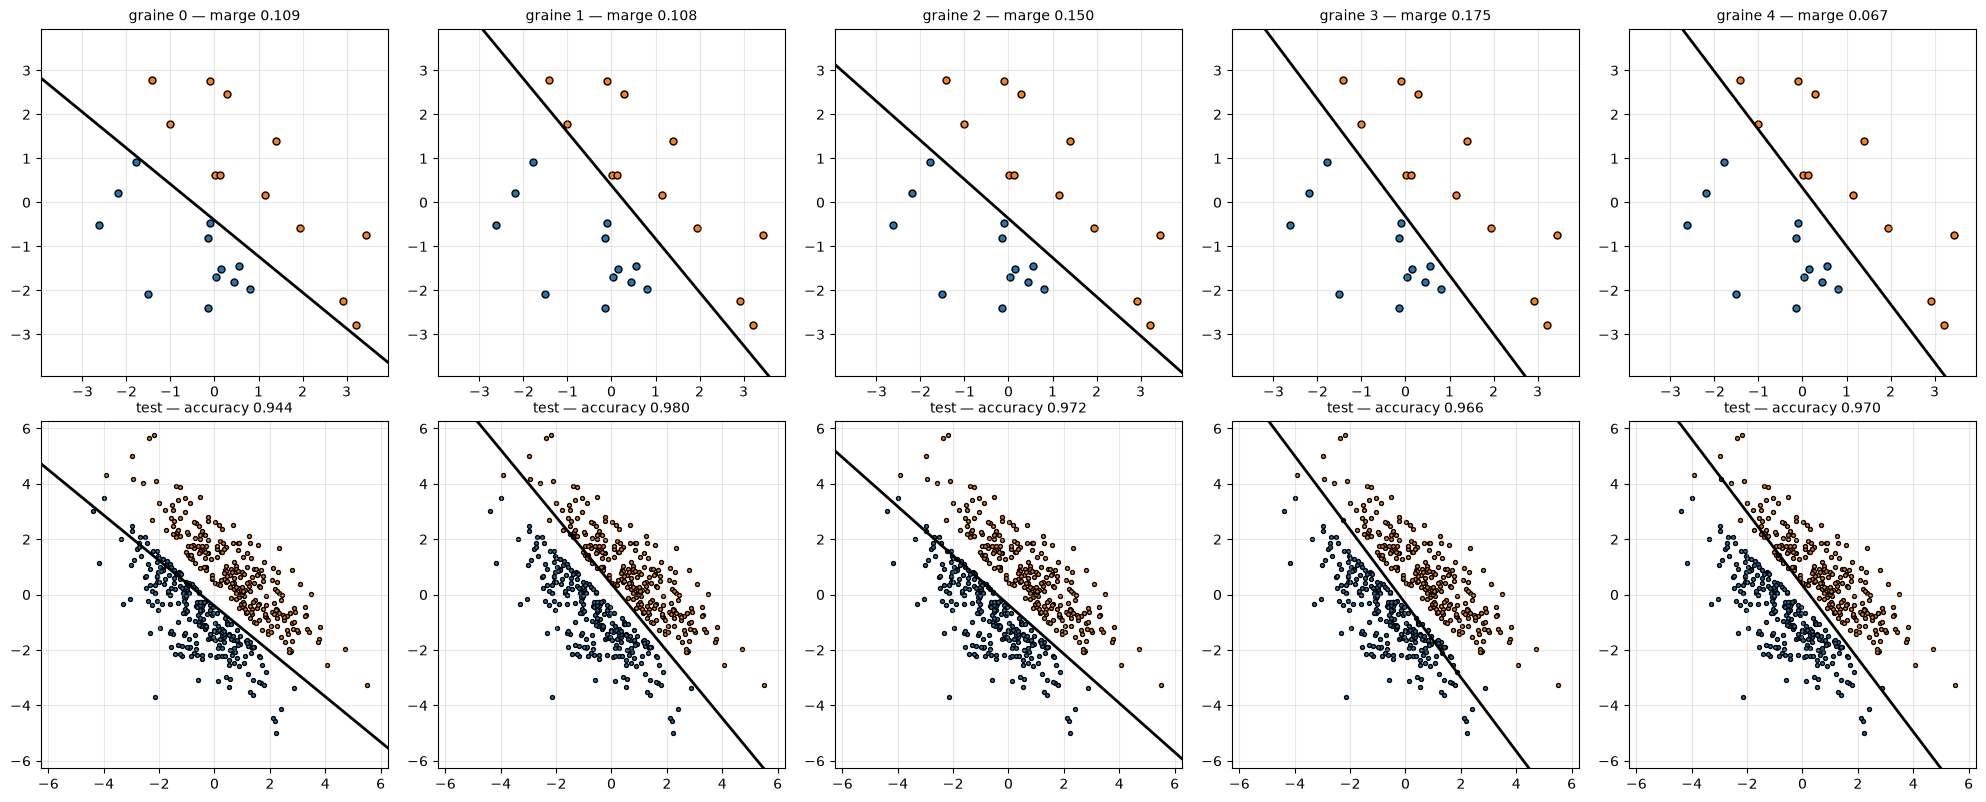

In [9]:
for g, p in zip(graines, perceptrons):
    print(f"graine {g} : {len(p.erreurs)} époques, marge = {marge(p.w, p.b, X_train, t_train):.3f}, "
          f"accuracy test = {accuracy(p.predict(X_test), t_test):.3f}")

fig, axes = plt.subplots(2, len(perceptrons), figsize=(4 * len(perceptrons), 8))
for g, p, ax_tr, ax_te in zip(graines, perceptrons, axes[0], axes[1]):
    plot_modele(ax_tr, X_train, t_train, p.w, p.b,
                titre=f"graine {g} — marge {marge(p.w, p.b, X_train, t_train):.3f}")
    plot_modele(ax_te, X_test, t_test, p.w, p.b,
                titre=f"test — accuracy {accuracy(p.predict(X_test), t_test):.3f}")
plt.tight_layout()
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 3</legend>

Les cinq perceptrons ont-ils trouvé la même droite ? Ont-ils tous convergé ? Que vaut leur marge, comparée à la largeur `ECART` = 0.6 de la bande vide ? Comment se comportent-ils sur le jeu de test ?

</fieldset>

*Votre réponse :*

# TOCLEAR

- Les cinq perceptrons convergent tous (en 2 ou 3 époques) : ils séparent parfaitement les 24 points d'entraînement. Mais ils trouvent **cinq droites différentes** : le résultat dépend de l'ordre de présentation des points (la graine).
- Leurs marges sont petites (entre 0.07 et 0.18 environ) : chaque droite **frôle** au moins un point d'entraînement. Une droite qui passerait au milieu de la bande vide aurait une marge d'au moins 0.3 (la moitié de l'écart), et sans doute davantage avec ces 24 points.
- Sur le test, aucune n'est parfaite (accuracy entre 94 % et 98 %) : les points de test proches de la frontière, du côté où la droite frôle les données, sont mal classés. Le perceptron s'arrête dès que l'erreur d'entraînement est nulle ; rien ne le pousse à choisir une droite « bien placée ».

## 2. SVM par descente de gradient

### 2.1 La classe `SVM`

On minimise la perte du cours (§3.2), où le biais $b$ n'est **pas** régularisé :

$$E(w, b) = \frac{1}{2}\|w\|^2 + \frac{C}{N} \sum_{i=1}^N \max\big(0,\ 1 - t_i z_i\big), \qquad z_i = w \cdot x_i + b$$

Son sous-gradient (§3.3) ne fait intervenir que les points qui **violent leur marge** ($t_i z_i < 1$, inégalité **stricte**) :

$$\frac{\partial E}{\partial w} = w - \frac{C}{N} \sum_{i \,:\, t_i z_i < 1} t_i\, x_i \qquad\qquad \frac{\partial E}{\partial b} = -\frac{C}{N} \sum_{i \,:\, t_i z_i < 1} t_i$$

Toutes les méthodes sont **vectorisées** (pas de boucle sur les points). On part de $w = 0$, $b = 0$.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 4a</legend>

Complétez `scores(X)` (renvoie le vecteur des $z_i$) et `predict(X)` (renvoie $+1$ si $z \ge 0$, $-1$ sinon).

</fieldset>

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 4b</legend>

Complétez `loss(X, t)` : la valeur de $E(w, b)$.

</fieldset>

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 4c</legend>

Complétez `gradient(X, t)` : renvoie le couple `(dw, db)` $= \left(\frac{\partial E}{\partial w}, \frac{\partial E}{\partial b}\right)$.

</fieldset>

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 4d</legend>

Complétez `fit(X, t, lr, epochs)` : descente de gradient **batch** ($w \leftarrow w - \texttt{lr}\; dw$, $b \leftarrow b - \texttt{lr}\; db$), répétée `epochs` fois ; à la fin de chaque époque, ajoutez la perte $E$ à `self.pertes`. Renvoie `self`.

</fieldset>

In [10]:
class SVM:
    def __init__(self, d: int, C: float = 100.0):
        self.w = np.zeros(d)
        self.b = 0.0
        self.C = C
        self.pertes = []

    def scores(self, X: Mat) -> Vec:
        # BEGIN
        # raise NotImplementedError
        ## Indice : un seul produit matrice-vecteur (@), plus le biais
        return X @ self.w + self.b
        # END

    def predict(self, X: Mat) -> VecInt:
        # BEGIN
        # raise NotImplementedError
        ## Indice : np.where(condition, 1, -1)
        return np.where(self.scores(X) >= 0, 1, -1)
        # END

    def loss(self, X: Mat, t: VecInt) -> float:
        # BEGIN
        # raise NotImplementedError
        ## Indice : on a l'identité ||w||² = w @ w
        hinge = np.maximum(0.0, 1 - t * self.scores(X))
        return float((self.w @ self.w) / 2 + self.C * hinge.mean())
        # END

    def gradient(self, X: Mat, t: VecInt) -> tuple[Vec, float]:
        # BEGIN
        # raise NotImplementedError
        ## Indice : masque selected = t * z < 1 ; t[selected] @ X[selected] calcule la somme des t_i x_i
        N = len(X)
        selected = t * self.scores(X) < 1
        dw = self.w - self.C * (t[selected] @ X[selected]) / N
        db = -self.C * float(t[selected].sum()) / N
        return dw, db
        # END

    def fit(self, X: Mat, t: VecInt, lr: float = 0.001, epochs: int = 1000) -> "SVM":
        self.pertes = []
        # BEGIN
        # raise NotImplementedError
        ## Indice : dw, db = self.gradient(X, t) ; mise à jour de w et b ; self.pertes.append(self.loss(X, t))
        for _ in range(epochs):
            dw, db = self.gradient(X, t)
            self.w = self.w - lr * dw
            self.b = self.b - lr * db
            self.pertes.append(self.loss(X, t))
        return self
        # END

#### Vérification de `scores` et `predict`

In [11]:
def check_scores_predict():
    s = SVM(2)
    s.w = np.array([1.0, -2.0])
    s.b = 1.0
    X = np.array([[0.0, 0.0], [1.0, 1.0], [0.0, 1.0], [-1.0, 0.0]])
    assert np.array_equal(s.scores(X), np.array([1.0, 0.0, -1.0, 0.0]))
    assert np.array_equal(s.predict(X), np.array([1, 1, -1, 1]))   # z = 0 -> +1
    print("scores / predict check — OK")


check_scores_predict()

scores / predict check — OK


#### Vérification de `loss`

Calcul à la main, avec $C = 3$ : avec $w = (1, 0)$, $b = 0$ et trois points de cible $+1$, les $t_i z_i$ valent $2,\ 0.5,\ -1$, donc les pertes hinge $0,\ 0.5,\ 2$ (moyenne $2.5/3$, multipliée par $C$ : $2.5$) ; la régularisation vaut $\frac{1}{2} \times 1 = 0.5$. Avec $b = 1$ (même $w$), les $t_i z_i$ valent $3,\ 1.5,\ 0$ : pertes hinge $0,\ 0,\ 1$ (terme hinge : $C \times 1/3 = 1$), et la régularisation ne change pas ($b$ n'est pas régularisé).

In [12]:
def check_loss():
    s = SVM(2, C=3.0)
    s.w = np.array([1.0, 0.0])
    s.b = 0.0
    X = np.array([[2.0, 0.0], [0.5, 0.0], [-1.0, 0.0]])
    t = np.array([1, 1, 1])
    assert s.loss(X, t) == 3.0, s.loss(X, t)
    s.b = 1.0
    assert s.loss(X, t) == 1.5, "b ne doit pas être régularisé"
    print("loss check — OK")


check_loss()

loss check — OK


#### Vérification de `gradient`

On compare `gradient` à des **différences finies** : $\frac{\partial E}{\partial w_j} \approx \frac{E(w + \epsilon e_j) - E(w - \epsilon e_j)}{2\epsilon}$, sur des données et des paramètres aléatoires (aucun point n'est exactement sur sa marge, là où la hinge n'est pas dérivable).

In [13]:
def check_gradient(eps=1e-6):
    rng = np.random.default_rng(0)
    X = rng.normal(size=(20, 2))
    t = np.where(rng.random(20) < 0.5, 1, -1)
    s = SVM(2, C=3.0)
    s.w = rng.normal(size=2)
    s.b = float(rng.normal())
    assert np.min(np.abs(t * s.scores(X) - 1)) > 1e-3   # pas de point sur t z = 1
    dw, db = s.gradient(X, t)
    w0, b0 = s.w.copy(), s.b
    for j in range(2):
        e = np.zeros(2)
        e[j] = eps
        s.w = w0 + e
        Ep = s.loss(X, t)
        s.w = w0 - e
        Em = s.loss(X, t)
        s.w = w0
        assert np.isclose(dw[j], (Ep - Em) / (2 * eps), atol=1e-6), f"dw[{j}] incorrect"
    s.b = b0 + eps
    Ep = s.loss(X, t)
    s.b = b0 - eps
    Em = s.loss(X, t)
    s.b = b0
    assert np.isclose(db, (Ep - Em) / (2 * eps), atol=1e-6), "db incorrect"
    print("gradient check — OK")


check_gradient()

gradient check — OK


#### Vérification de `fit`

Deux époques simulées à la main, avec $C = 2$, `lr` $= 0.25$, $X = \{(2, 0), (0, 2)\}$, $t = (+1, -1)$ :
- époque 1 : $w = 0$, donc $t_i z_i = 0 < 1$ pour les deux points : $dw = -\frac{2}{2}\big((2, 0) - (0, 2)\big) = (-2, 2)$, $db = -\frac{2}{2}(1 - 1) = 0$, d'où $w = (0.5, -0.5)$, $b = 0$. Ensuite $t_i z_i = 1$ pour les deux points : perte hinge nulle, $E = \frac{1}{2} \times 0.5 = 0.25$ ;
- époque 2 : $t_i z_i = 1$ n'est **pas** $< 1$ : seul le terme $w$ reste, $dw = (0.5, -0.5)$, $db = 0$, d'où $w = (0.375, -0.375)$, $b = 0$. Alors $t_i z_i = 0.75$ : hinge $0.25$ pour chaque point, et $E = \frac{1}{2} \times 0.28125 + 2 \times 0.25 = 0.640625$.

On vérifie aussi que `fit` renvoie le modèle lui-même (`self`).

In [14]:
def check_fit():
    s = SVM(2, C=2.0)
    X = np.array([[2.0, 0.0], [0.0, 2.0]])
    t = np.array([1, -1])
    assert s.fit(X, t, lr=0.25, epochs=2) is s, "fit doit renvoyer self"
    assert np.array_equal(s.w, np.array([0.375, -0.375])), s.w
    assert s.b == 0.0, s.b
    assert s.pertes == [0.25, 0.640625], s.pertes
    print("fit check — OK")


check_fit()

fit check — OK


La cellule suivante entraîne un SVM sur `(X_train, t_train)` et affiche sa courbe de perte : elle doit décroître puis se stabiliser.

perte initiale : 0.8729, perte finale : 0.0288


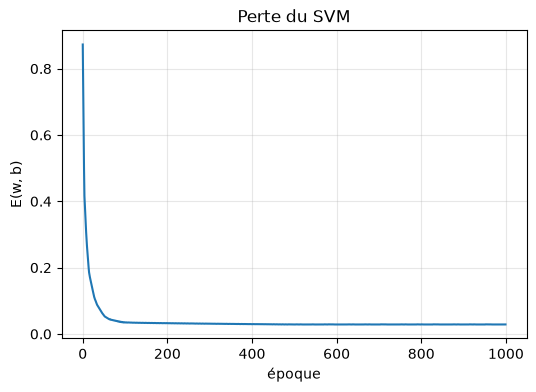

In [15]:
s = SVM(2, C=100.0).fit(X_train, t_train, lr=0.001, epochs=1000)
print(f"perte initiale : {s.pertes[0]:.4f}, perte finale : {s.pertes[-1]:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(s.pertes)
ax.set_xlabel("époque")
ax.set_ylabel("E(w, b)")
ax.set_title("Perte du SVM")
ax.grid(True, alpha=0.3)
plt.show()

### 2.2 Comparaison avec le perceptron

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 5</legend>

Entraînez un `SVM(2, C=100.0)` sur `(X_train, t_train)` avec `lr=0.001` et `epochs=1000`, et rangez-le dans la variable `svm`.

</fieldset>

Après la vérification, la cellule suivante affiche la marge sur le jeu d'entraînement et l'accuracy sur le jeu de test du SVM et des perceptrons de l'exercice 2.

In [16]:
# BEGIN
## Rappel : SVM(d, C) crée le modèle, .fit(X, t, lr, epochs) l'entraîne et le renvoie
# svm = ...
svm = SVM(2, C=100.0).fit(X_train, t_train, lr=0.001, epochs=1000)
# END

#### Vérification

In [17]:
assert accuracy(svm.predict(X_test), t_test) >= max(accuracy(p.predict(X_test), t_test) for p in perceptrons)
assert marge(svm.w, svm.b, X_train, t_train) > max(marge(p.w, p.b, X_train, t_train) for p in perceptrons)
print("comparaison SVM / perceptrons — OK")

comparaison SVM / perceptrons — OK


In [18]:
print(f"SVM : marge = {marge(svm.w, svm.b, X_train, t_train):.3f}, "
      f"accuracy test = {accuracy(svm.predict(X_test), t_test):.3f}")
for g, p in zip(graines, perceptrons):
    print(f"perceptron graine {g} : marge = {marge(p.w, p.b, X_train, t_train):.3f}, "
          f"accuracy test = {accuracy(p.predict(X_test), t_test):.3f}")

SVM : marge = 0.417, accuracy test = 1.000
perceptron graine 0 : marge = 0.109, accuracy test = 0.944
perceptron graine 1 : marge = 0.108, accuracy test = 0.980
perceptron graine 2 : marge = 0.150, accuracy test = 0.972
perceptron graine 3 : marge = 0.175, accuracy test = 0.966
perceptron graine 4 : marge = 0.067, accuracy test = 0.970


La cellule suivante affiche le SVM avec ses marges $z = \pm 1$ (pointillés) et ses **vecteurs de support** (entourés) : à gauche sur le jeu d'entraînement, à droite sur le jeu de test.

La descente de gradient **approche** la marge maximale sans l'atteindre exactement : le pas `lr` est fixe (le sous-gradient fait osciller $w$ autour de l'optimum) et $C$ fini tolère quelques points très légèrement à l'intérieur de la marge. Les vecteurs de support vérifient donc $t\,z \approx 1$ et non $t\,z = 1$ exactement : c'est pour cela que `plot_modele` entoure les points tels que $t\,z \le 1 + \varepsilon$. Un solveur de programmation quadratique (cours §2.3) donnerait la solution exacte.

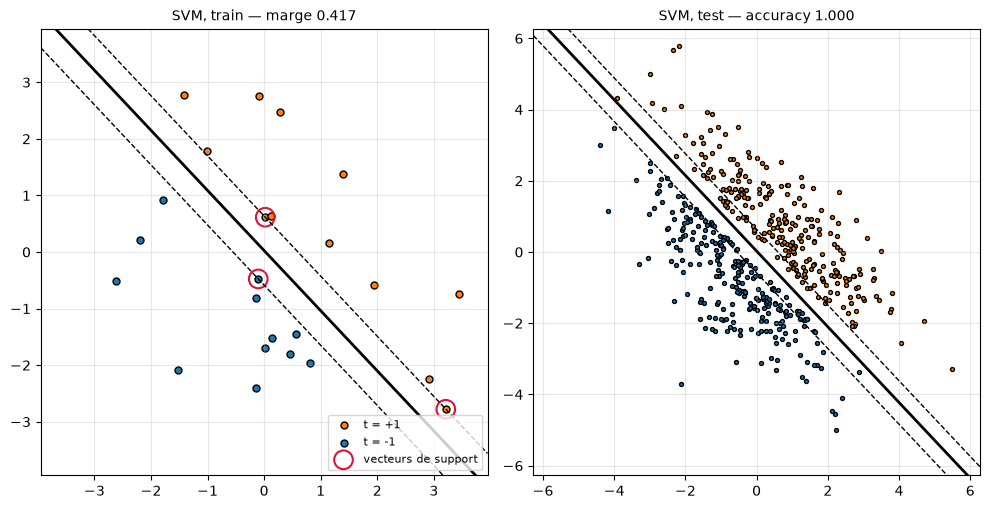

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_modele(axes[0], X_train, t_train, svm.w, svm.b, marges=True, supports=True,
            titre=f"SVM, train — marge {marge(svm.w, svm.b, X_train, t_train):.3f}")
plot_modele(axes[1], X_test, t_test, svm.w, svm.b, marges=True,
            titre=f"SVM, test — accuracy {accuracy(svm.predict(X_test), t_test):.3f}")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 6</legend>

Comparez la marge et l'accuracy test du SVM à celles des perceptrons. Combien y a-t-il de vecteurs de support, et où la frontière du SVM se place-t-elle par rapport à eux ?

</fieldset>

*Votre réponse :*

# TOCLEAR

- La marge du SVM (≈ 0.42) est plus du double de la meilleure marge des perceptrons (≈ 0.18) : la frontière passe **au milieu** de la bande vide au lieu de frôler un point.
- Sur le test, le SVM classe correctement tous les points (accuracy 100 %), contre 94 % à 98 % pour les perceptrons : laisser de la place de chaque côté rend la frontière robuste aux points de test proches de la bande.
- Il y a 3 vecteurs de support, situés sur les deux droites en pointillés ($t\,z \approx 1$), et la frontière est à égale distance des deux classes. Ce sont eux seuls qui fixent la frontière : déplacer un autre point (sans le faire entrer dans la marge) ne la changerait pas. Contrairement aux perceptrons, le résultat ne dépend d'aucune graine.

## 3. Données bruitées

On reprend **les mêmes 24 points** d'entraînement, mais on inverse l'étiquette de 3 d'entre eux (`n_bruit=3`) : le jeu n'est plus séparable. Le jeu de test, lui, n'est pas modifié. Dans la figure, les 3 points bruités sont marqués d'une croix.

points bruités : [ 2 16 17]


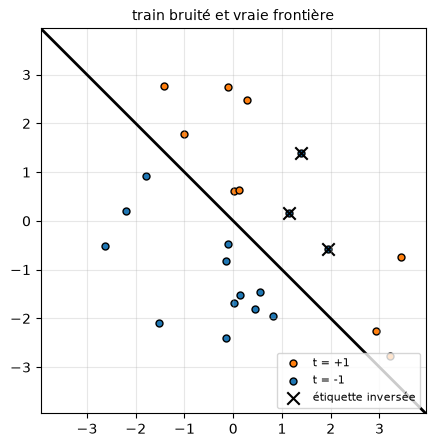

In [21]:
X_bruit, t_bruit = gen_donnees(24, ECART, seed=4, n_bruit=3)
bruit = t_bruit != t_train
print("points bruités :", np.where(bruit)[0])

fig, ax = plt.subplots(figsize=(5, 5))
plot_modele(ax, X_bruit, t_bruit, np.array([1.0, 1.0]), 0.0, titre="train bruité et vraie frontière")
ax.scatter(X_bruit[bruit, 0], X_bruit[bruit, 1], marker="x", c="k", s=80, label="étiquette inversée")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### 3.1 Perceptron et SVM sur données bruitées

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 7</legend>

Sur `(X_bruit, t_bruit)` : entraînez un `Perceptron(2)` nommé `perceptron` (avec `max_epochs=100`, `seed=0`) en rangeant le nombre d'époques renvoyé dans `n_epochs`, puis un `SVM(2, C=100.0)` nommé `svm_bruit` (`lr=0.001`, `epochs=1000`).

</fieldset>

In [22]:
# BEGIN
## Rappel : même démarche qu'aux exercices 2 et 5, sur (X_bruit, t_bruit)
# perceptron = ...
# n_epochs = ...
# svm_bruit = ...
perceptron = Perceptron(2)
n_epochs = perceptron.fit(X_bruit, t_bruit, max_epochs=100, seed=0)
svm_bruit = SVM(2, C=100.0).fit(X_bruit, t_bruit, lr=0.001, epochs=1000)
# END

#### Vérification

In [23]:
assert n_epochs == 100, "le perceptron ne doit pas converger : vérifiez max_epochs=100"
assert len(perceptron.erreurs) == 100 and len(svm_bruit.pertes) == 1000
assert accuracy(svm_bruit.predict(X_test), t_test) > accuracy(perceptron.predict(X_test), t_test)
print("données bruitées — OK")

données bruitées — OK


La cellule suivante affiche l'accuracy test des deux modèles, puis, en haut, le nombre d'erreurs du perceptron à chaque époque et la perte du SVM ; en bas, les deux frontières sur le jeu d'entraînement bruité (croix : étiquettes inversées) et sur le jeu de test.

perceptron : 100 époques, accuracy test = 0.748
SVM        : accuracy test = 1.000


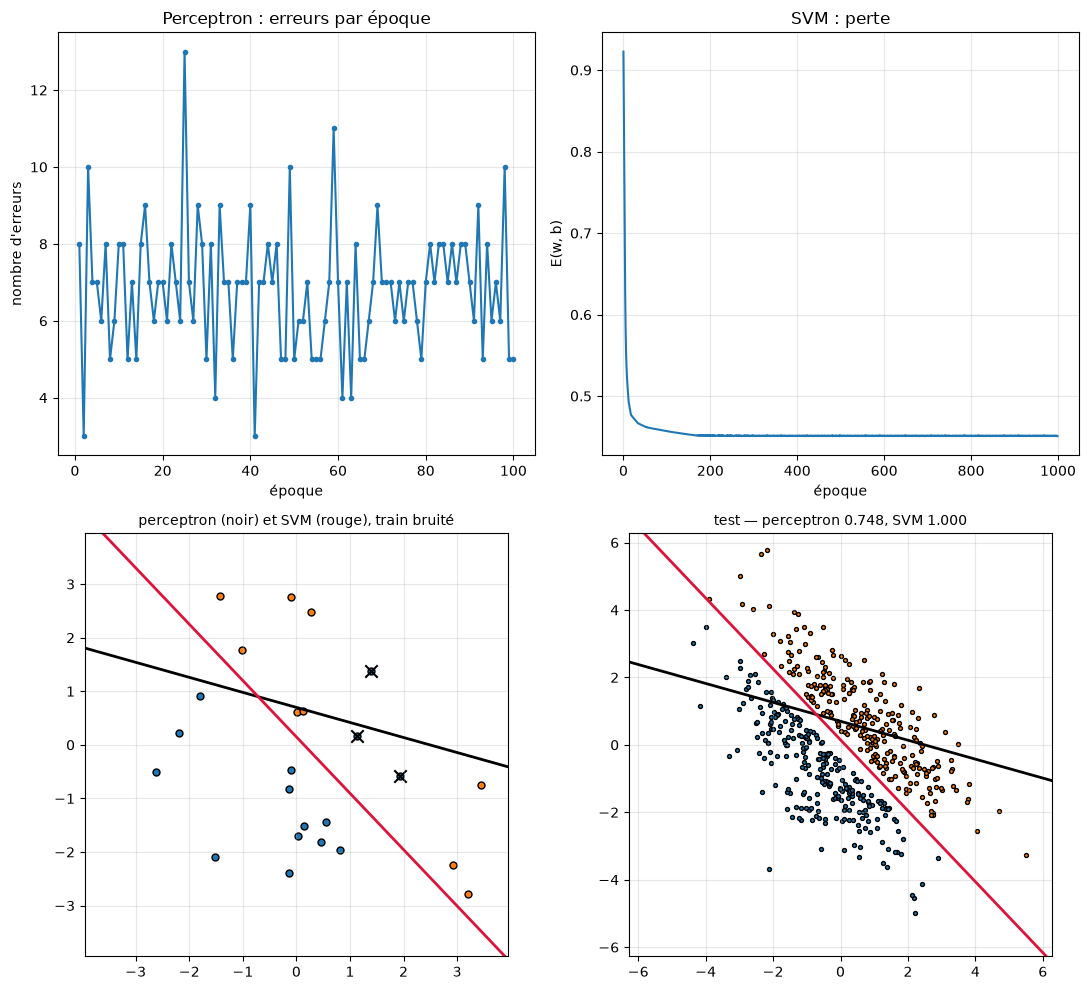

In [24]:
print(f"perceptron : {n_epochs} époques, accuracy test = {accuracy(perceptron.predict(X_test), t_test):.3f}")
print(f"SVM        : accuracy test = {accuracy(svm_bruit.predict(X_test), t_test):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes[0, 0].plot(range(1, len(perceptron.erreurs) + 1), perceptron.erreurs, marker=".")
axes[0, 0].set_xlabel("époque")
axes[0, 0].set_ylabel("nombre d'erreurs")
axes[0, 0].set_title("Perceptron : erreurs par époque")
axes[0, 0].grid(True, alpha=0.3)
axes[0, 1].plot(svm_bruit.pertes)
axes[0, 1].set_xlabel("époque")
axes[0, 1].set_ylabel("E(w, b)")
axes[0, 1].set_title("SVM : perte")
axes[0, 1].grid(True, alpha=0.3)

plot_modele(axes[1, 0], X_bruit, t_bruit, perceptron.w, perceptron.b, titre="perceptron (noir) et SVM (rouge), train bruité")
axes[1, 0].scatter(X_bruit[bruit, 0], X_bruit[bruit, 1], marker="x", c="k", s=80)
plot_modele(axes[1, 1], X_test, t_test, perceptron.w, perceptron.b,
            titre=f"test — perceptron {accuracy(perceptron.predict(X_test), t_test):.3f}, "
                  f"SVM {accuracy(svm_bruit.predict(X_test), t_test):.3f}")
for ax in axes[1]:
    p0 = -svm_bruit.b * svm_bruit.w / (svm_bruit.w @ svm_bruit.w)
    ax.axline(p0, p0 + np.array([-svm_bruit.w[1], svm_bruit.w[0]]), color="crimson", lw=2)
plt.tight_layout()
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 8</legend>

Le perceptron converge-t-il ? Pourquoi ? Comment évolue la perte du SVM ? Comparez les frontières et les accuracies test des deux modèles.

</fieldset>

*Votre réponse :*

# TOCLEAR

- Le perceptron **ne converge pas** : il va jusqu'à `max_epochs` = 100 époques, avec un nombre d'erreurs qui oscille (de 3 à 13 par époque, le plus souvent 5 à 8) sans jamais atteindre 0. C'est inévitable : aucune droite ne sépare des données non séparables, donc il y a toujours un point mal classé qui déclenche une mise à jour. Sa frontière finale dépend des dernières mises à jour (elle « saute » d'une époque à l'autre) ; ici elle est mal placée et son accuracy test tombe à 75 %.
- La perte du SVM **décroît puis se stabilise** (de 92 à 45 environ) : $E$ est convexe, et la descente de gradient en approche le minimum. La perte hinge accepte de payer pour les 3 points bruités au lieu de chercher à les classer à tout prix.
- Le SVM se trompe sur les 3 points bruités (accuracy train 21/24) mais garde une frontière proche de la vraie : accuracy test 100 %. Le SVM à marge souple est **stable** face au bruit, le perceptron non.

### 3.2 Effet de $C$

Plus $C$ est grand, plus la perte $E$ pénalise les erreurs de marge (hinge) par rapport à $\|w\|^2$. On mesure la marge par $1/\|w\|$, distance entre la frontière $z = 0$ et chaque droite $z = \pm 1$ (cours §2.2) ; sur des données non séparables, la « marge » `marge(w, b, X, t)` de l'exercice 1 serait négative et ne dit plus rien. Les vecteurs de support sont les points tels que $t\,z \le 1$ : sur la marge, à l'intérieur ou mal classés.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 9</legend>

Pour chaque valeur de `Cs`, entraînez un `SVM(2, C=C)` sur `(X_bruit, t_bruit)` avec `lr=0.1 / C` et `epochs=1000`, et ajoutez-le à la liste `svms_C`. Le gradient de la perte hinge est proportionnel à $C$ : on réduit le pas d'autant.

</fieldset>

Après la vérification, la cellule suivante affiche chaque modèle avec ses marges et ses vecteurs de support ($t\,z \le 1 + 0.05$) ; le titre indique $C$, la marge $1/\|w\|$ et le nombre de vecteurs de support.

In [ ]:
Cs = [1.0, 10.0, 100.0]
svms_C = []
# BEGIN
# for C in Cs:
#     svms_C.append(...)
for C in Cs:
    svms_C.append(SVM(2, C=C).fit(X_bruit, t_bruit, lr=0.1 / C, epochs=1000))
# END

#### Vérification

La cellule vérifie que la marge $1/\|w\|$ décroît quand $C$ augmente.

In [ ]:
assert len(svms_C) == len(Cs), "il faut un SVM par valeur de C"
marges_C = [1 / np.linalg.norm(s.w) for s in svms_C]
assert all(m1 > m2 for m1, m2 in zip(marges_C, marges_C[1:])), "1/‖w‖ doit décroître quand C augmente"
print("effet de C — OK")

La cellule suivante affiche l'accuracy de chaque modèle sur le train bruité et sur le test, puis les trois modèles.

In [ ]:
for C, s in zip(Cs, svms_C):
    print(f"C = {C:<5} : 1/‖w‖ = {1 / np.linalg.norm(s.w):.2f}, accuracy train = {accuracy(s.predict(X_bruit), t_bruit):.3f}, "
          f"accuracy test = {accuracy(s.predict(X_test), t_test):.3f}")

fig, axes = plt.subplots(1, len(Cs), figsize=(5 * len(Cs), 5))
for C, s, ax in zip(Cs, svms_C, axes):
    n_sv = int(np.sum(t_bruit * s.scores(X_bruit) <= 1 + 0.05))
    plot_modele(ax, X_bruit, t_bruit, s.w, s.b, marges=True, supports=True,
                titre=f"C = {C} — marge 1/‖w‖ = {1 / np.linalg.norm(s.w):.2f} — {n_sv} vecteurs de support")
plt.tight_layout()
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 10</legend>

La vérification et l'affichage montrent que la marge $1/\|w\|$ décroît quand $C$ augmente : expliquez pourquoi à partir de $E$. Que devient le nombre de vecteurs de support ? Que se passe-t-il pour $C$ trop petit ? Comment choisiriez-vous $C$ ?

</fieldset>

*Votre réponse :*

# TOCLEAR

- Quand $C$ diminue, les erreurs de marge (hinge) coûtent moins cher par rapport à $\|w\|^2$ : $\|w\|$ diminue et la marge $1/\|w\|$ **s'élargit** (≈ 0.77, 1.28 puis 2.45 pour $C$ = 100, 10 puis 1). De plus en plus de points tombent dans la bande, donc le nombre de vecteurs de support **augmente** (13, 16 puis 20 sur 24).
- Grand $C$ : la perte hinge domine, le SVM cherche surtout à respecter les marges (il reste les 3 erreurs dues au bruit, inévitables) ; accuracy test 100 %.
- $C$ trop petit : la marge est si large que presque tous les points la violent ; le modèle accepte des erreurs d'entraînement pour garder $w$ petit et la frontière se dégrade (accuracy test ≈ 89 % pour $C = 10$, ≈ 66 % pour $C = 1$) : c'est du **sous-apprentissage**. Pour $C = 1$, $w$ est si petit que $z \approx b$ pour presque tous les points : le biais (non régularisé) dérive vers la classe majoritaire du train bruité (15 points $t = -1$ contre 9 $t = +1$), la frontière se décale vers les $+1$ (84 % des points de test prédits $-1$) ; d'où une accuracy train non monotone (75 %, 66.7 %, 87.5 % pour $C$ = 1, 10, 100).
- $C$ **arbitre entre marge large et erreurs d'entraînement**. C'est un hyperparamètre : on le choisit en comparant plusieurs valeurs sur des données de validation (pas sur le test).

## Bonus : SVM non linéaire avec $\Phi$

Comme au cours 3, deux classes en **cercles concentriques** ne sont pas linéairement séparables dans le plan : $t = +1$ pour les points de rayon $r < 1$, $t = -1$ pour ceux de rayon $1.5 < r < 2.5$. En ajoutant la coordonnée $x_1^2 + x_2^2 = r^2$, elles deviennent séparables par un **plan** dans $\mathbb{R}^3$ : le même `SVM` linéaire suffit, appliqué à $\Phi(x)$ au lieu de $x$.

In [ ]:
def gen_cercles(n: int, seed: int) -> tuple[Mat, VecInt]:
    rng = np.random.default_rng(seed)
    t = np.where(np.arange(n) < n // 2, 1, -1)
    r = np.where(t == 1, rng.uniform(0.0, 1.0, n), rng.uniform(1.5, 2.5, n))
    theta = rng.uniform(0.0, 2 * np.pi, n)
    X = np.column_stack([r * np.cos(theta), r * np.sin(theta)])
    return X, t


X_c, t_c = gen_cercles(200, seed=0)
fig, ax = plt.subplots(figsize=(5, 5))
plot_modele(ax, X_c, t_c, np.zeros(2), 0.0, titre="cercles concentriques")
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 11a</legend>

Complétez `phi(X)` : renvoie la matrice $(N, 3)$ dont la ligne $i$ est $\Phi(x_i) = (x_{i1},\ x_{i2},\ x_{i1}^2 + x_{i2}^2)$.

</fieldset>

In [ ]:
def phi(X: Mat) -> Mat:
    # BEGIN
    # raise NotImplementedError
    ## Indice : np.column_stack ; (X ** 2).sum(axis=1) donne les x1² + x2²
    return np.column_stack([X, (X ** 2).sum(axis=1)])
    # END

#### Vérification de `phi`

In [ ]:
def check_phi():
    X = np.array([[1.0, 2.0], [0.0, -3.0]])
    assert np.array_equal(phi(X), np.array([[1.0, 2.0, 5.0], [0.0, -3.0, 9.0]])), phi(X)
    print("phi check — OK")


check_phi()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 11b</legend>

Entraînez un `SVM(3, C=100.0)` nommé `svm_c` sur `(phi(X_c), t_c)` (`lr=0.001`, `epochs=1000`).

</fieldset>

In [ ]:
# BEGIN
## Rappel : la classe SVM ne change pas, seule la dimension d'entrée passe à 3
# svm_c = ...
svm_c = SVM(3, C=100.0).fit(phi(X_c), t_c, lr=0.001, epochs=1000)
# END

#### Vérification

In [ ]:
assert accuracy(svm_c.predict(phi(X_c)), t_c) >= 0.95
print("SVM sur Φ(x) — OK")

La frontière est un plan dans l'espace de $\Phi(x)$ ; dans le plan d'origine, c'est la courbe $w_1 x_1 + w_2 x_2 + w_3 (x_1^2 + x_2^2) + b = 0$, ici presque un cercle. La cellule suivante la trace en évaluant le score sur une grille (`contour` au niveau 0, marges aux niveaux $\pm 1$).

In [ ]:
g1, g2 = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
grille = np.column_stack([g1.ravel(), g2.ravel()])
Z = svm_c.scores(phi(grille)).reshape(g1.shape)

fig, ax = plt.subplots(figsize=(5, 5))
plot_modele(ax, X_c, t_c, np.zeros(2), 0.0, titre=f"SVM sur Φ(x) — accuracy train {accuracy(svm_c.predict(phi(X_c)), t_c):.3f}")
ax.contour(g1, g2, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
plt.show()

## À retenir

- **Données séparables** : le perceptron s'arrête sur *une* droite séparatrice quelconque, qui dépend de l'ordre de présentation des points et frôle souvent un point. Le SVM trouve *la* droite de **marge maximale**, unique, fixée par quelques vecteurs de support, et elle généralise mieux.
- **Données bruitées** : le perceptron ne converge pas et oscille ; le SVM à marge souple (perte hinge) reste stable et garde une bonne frontière.
- **Régularisation** : $C$ arbitre entre marge large et erreurs d'entraînement ; trop petit, il conduit au sous-apprentissage.
- Le SVM à marge souple se minimise par simple **descente de (sous-)gradient** ; remplacer $x$ par $\Phi(x)$ le rend non linéaire sans rien changer au code.